# Reto avanzado 2: reducción de dimensionalidad (PCA) y visualización

Se aplica PCA sobre las 14 features escaladas del reto 2 para:
1. Medir la varianza explicada por cada componente y la acumulada.
2. Visualizar los clústeres de K-Means (reto 3) en 2D y 3D.
3. Interpretar qué variables pesan en cada componente.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
from sklearn.decomposition import PCA

X = pd.read_csv(PROC / "features_modelo.csv", dtype={"client_id": str}).set_index("client_id")
labels = pd.read_csv(PROC / "segmentos_kmeans.csv", dtype={"client_id": str}).set_index("client_id").cluster.reindex(X.index)
nombres_path = PROC / "nombres_segmentos.csv"
NOMBRES = (pd.read_csv(nombres_path).set_index("cluster").nombre.to_dict() if nombres_path.exists()
           else {c: f"clúster {c}" for c in sorted(labels.unique())})
K = labels.nunique()

pca = PCA(random_state=SEED).fit(X)
var = pd.DataFrame({"varianza explicada %": pca.explained_variance_ratio_ * 100,
                    "acumulada %": pca.explained_variance_ratio_.cumsum() * 100},
                   index=[f"PC{i + 1}" for i in range(X.shape[1])])
var.round(2)

,varianza explicada %,acumulada %
PC1,16.020,16.020
PC2,12.210,28.230
PC3,10.500,38.740
PC4,9.790,48.530
PC5,8.390,56.910
PC6,8.260,65.170
PC7,8.010,73.180
PC8,6.900,80.080
PC9,5.880,85.950
PC10,4.820,90.770


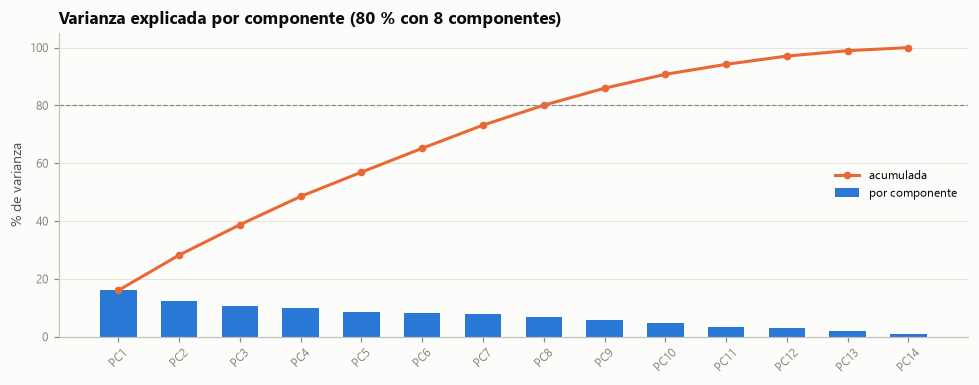

PC1 y PC2 explican el **28.2 %** de la varianza y las tres primeras el **38.7 %**. Hacen falta **8 componentes** para llegar al 80 %: la información está repartida entre muchas dimensiones (las features son casi independientes, ver el reto 2).

In [3]:
n80 = int((var["acumulada %"] >= 80).values.argmax()) + 1
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(var.index, var["varianza explicada %"], width=0.6, color=BLUE, label="por componente")
ax.plot(var.index, var["acumulada %"], color=CAT[1], lw=2, marker="o", ms=4, label="acumulada")
ax.axhline(80, color=MUTED, lw=0.8, ls="--")
ax.set_ylabel("% de varianza"); ax.set_ylim(0, 105); ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="center right")
ax.set_title(f"Varianza explicada por componente (80 % con {n80} componentes)")
save(fig, "a2_varianza_explicada.png")
show_md(f"PC1 y PC2 explican el **{var['acumulada %'].iloc[1]:.1f} %** de la varianza y las tres primeras el "
        f"**{var['acumulada %'].iloc[2]:.1f} %**. Hacen falta **{n80} componentes** para llegar al 80 %: "
        "la información está repartida entre muchas dimensiones (las features son casi independientes, ver el reto 2).")

## Proyección 2D y 3D coloreada por clúster

Se dibuja una muestra de 20.000 clientes para que el gráfico se pueda leer. Las cruces negras son los centroides proyectados.

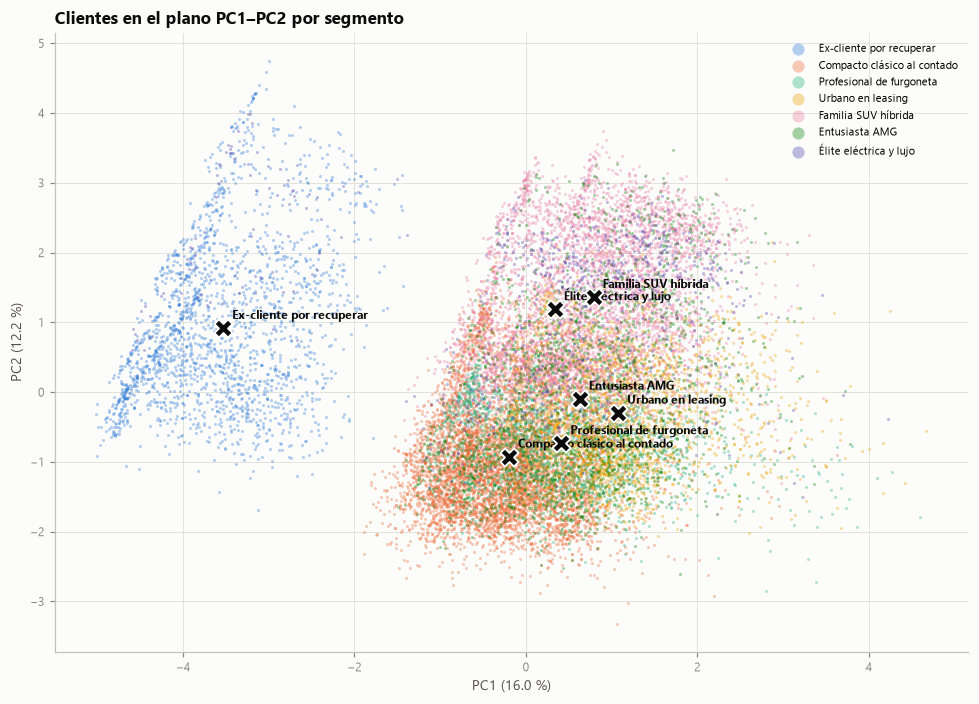

In [4]:
Z = pca.transform(X)[:, :3]
rng = np.random.default_rng(SEED)
m = rng.choice(len(X), size=20_000, replace=False)
cent = pd.DataFrame(Z[:, :3]).groupby(labels.to_numpy()).mean()
palette = (CAT * 2)[:K]

fig, ax = plt.subplots(figsize=(9, 6.5))
for c in range(K):
    sel = m[labels.to_numpy()[m] == c]
    ax.scatter(Z[sel, 0], Z[sel, 1], s=4, alpha=0.35, color=palette[c], label=NOMBRES.get(c, c), linewidths=0)
ax.scatter(cent[0], cent[1], marker="X", s=140, color=INK, edgecolor="white", linewidth=1.2, zorder=5)
for c in range(K):
    ax.annotate(NOMBRES.get(c, c), (cent.loc[c, 0], cent.loc[c, 1]), xytext=(6, 6), textcoords="offset points",
                fontsize=8, color=INK, fontweight="bold")
ax.set_xlabel(f"PC1 ({var.iloc[0, 0]:.1f} %)"); ax.set_ylabel(f"PC2 ({var.iloc[1, 0]:.1f} %)")
ax.legend(markerscale=4, loc="best", fontsize=7.5)
ax.set_title("Clientes en el plano PC1–PC2 por segmento")
save(fig, "a2_pca_2d.png")

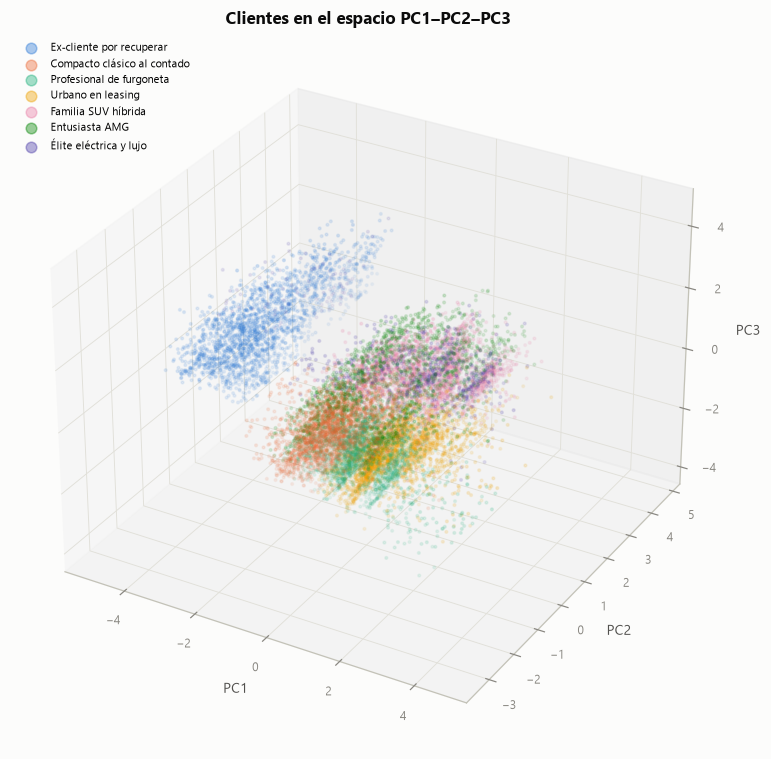

In [5]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
for c in range(K):
    sel = m[labels.to_numpy()[m] == c][:2500]
    ax.scatter(Z[sel, 0], Z[sel, 1], Z[sel, 2], s=3, alpha=0.4, color=palette[c], label=NOMBRES.get(c, c))
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.legend(markerscale=4, fontsize=7, loc="upper left")
ax.set_title("Clientes en el espacio PC1–PC2–PC3")
save(fig, "a2_pca_3d.png")

## Qué variables pesan en cada componente (loadings)

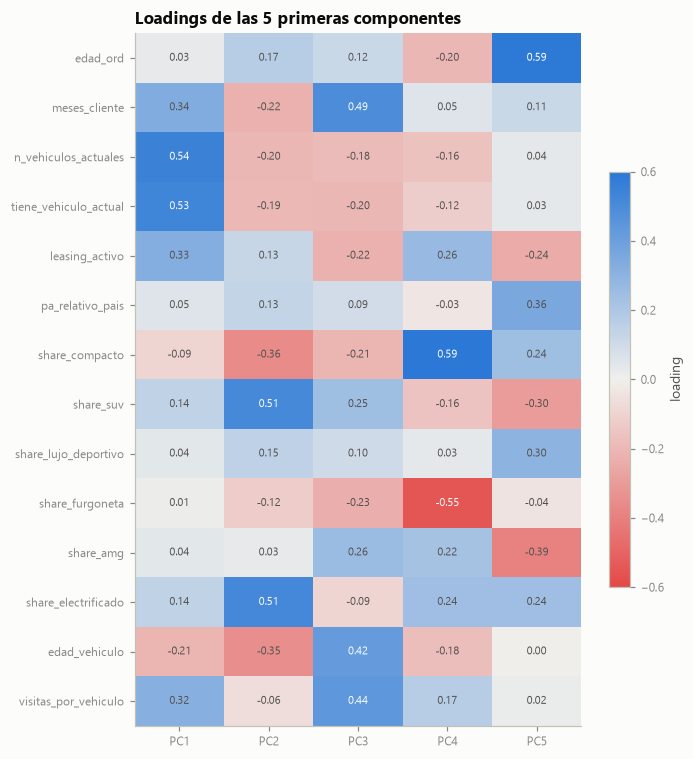

- **PC1**: `n_vehiculos_actuales` (+0.54), `tiene_vehiculo_actual` (+0.53), `meses_cliente` (+0.34), `leasing_activo` (+0.33)
- **PC2**: `share_electrificado` (+0.51), `share_suv` (+0.51), `share_compacto` (-0.36), `edad_vehiculo` (-0.35)
- **PC3**: `meses_cliente` (+0.49), `visitas_por_vehiculo` (+0.44), `edad_vehiculo` (+0.42), `share_amg` (+0.26)
- **PC4**: `share_compacto` (+0.59), `share_furgoneta` (-0.55), `leasing_activo` (+0.26), `share_electrificado` (+0.24)
- **PC5**: `edad_ord` (+0.59), `share_amg` (-0.39), `pa_relativo_pais` (+0.36), `share_lujo_deportivo` (+0.30)

In [6]:
load = pd.DataFrame(pca.components_[:5].T, index=X.columns, columns=[f"PC{i + 1}" for i in range(5)])
import matplotlib.colors as mcolors
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(load.values, cmap=mcolors.LinearSegmentedColormap.from_list("div", DIV), vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_yticks(range(len(load))); ax.set_yticklabels(load.index, fontsize=8)
ax.set_xticks(range(5)); ax.set_xticklabels(load.columns); ax.grid(False)
for i in range(len(load)):
    for j in range(5):
        ax.text(j, i, f"{load.values[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(load.values[i, j]) > 0.4 else INK2)
fig.colorbar(im, ax=ax, shrink=0.6, label="loading")
ax.set_title("Loadings de las 5 primeras componentes")
save(fig, "a2_loadings.png")

top = {pc: load[pc].abs().sort_values(ascending=False).head(4).index.tolist() for pc in load.columns}
show_md("\n".join(f"- **{pc}**: " + ", ".join(f"`{v}` ({load.loc[v, pc]:+.2f})" for v in vs) for pc, vs in top.items()))

## ¿Son los clústeres visualmente separables?

Se mide qué parte de la separación de K-Means se conserva en el plano 2D: el silhouette de los segmentos con las
coordenadas PC1–PC2 frente al silhouette en el espacio completo de 19 dimensiones (misma muestra).

In [7]:
from sklearn.metrics import silhouette_score

sub = m[:10_000]
s_full = silhouette_score(X.iloc[sub], labels.iloc[sub])
s_2d = silhouette_score(Z[sub, :2], labels.iloc[sub])
s_3d = silhouette_score(Z[sub, :3], labels.iloc[sub])
display(pd.Series({"espacio completo (14 dims)": s_full, "PC1–PC3": s_3d, "PC1–PC2": s_2d}, name="silhouette").to_frame())
show_md(f"""**Valoración:** en el plano PC1–PC2 los clústeres **no son visualmente separables** en su mayoría: el silhouette cae de
{s_full:.3f} (espacio completo) a {s_2d:.3f} (2D) y {s_3d:.3f} (3D), y las dos primeras componentes solo recogen el
{var['acumulada %'].iloc[1]:.0f} % de la varianza. Solo los **ex-clientes** (sin vehículo actual) forman un
grupo claramente aislado en PC1. Familia SUV y Élite eléctrica se desplazan hacia arriba (PC2: SUV electrificado), y
Compacto clásico hacia abajo a la izquierda. Furgonetas, AMG y leasing se solapan en este plano y se separan en
dimensiones posteriores (PC4: compacto frente a furgoneta; PC5: AMG). Esto es normal en datos de clientes
con muchas variables poco correlacionadas: la segmentación es válida en el espacio completo, pero un gráfico 2D no la
resume bien.

**Interpretación de las componentes:** PC1 = *vínculo actual con la marca* (vehículos actuales, leasing, antigüedad);
PC2 = *SUV electrificado frente a compacto antiguo*; PC3 = *antigüedad y mantenimiento* (meses como cliente, visitas,
edad del vehículo); PC4 = *compacto frente a furgoneta*; PC5 = *edad y poder adquisitivo*.""")

,silhouette
espacio completo (14 dims),0.186
PC1–PC3,0.080
PC1–PC2,0.050


**Valoración:** en el plano PC1–PC2 los clústeres **no son visualmente separables** en su mayoría: el silhouette cae de
0.186 (espacio completo) a 0.050 (2D) y 0.080 (3D), y las dos primeras componentes solo recogen el
28 % de la varianza. Solo los **ex-clientes** (sin vehículo actual) forman un
grupo claramente aislado en PC1. Familia SUV y Élite eléctrica se desplazan hacia arriba (PC2: SUV electrificado), y
Compacto clásico hacia abajo a la izquierda. Furgonetas, AMG y leasing se solapan en este plano y se separan en
dimensiones posteriores (PC4: compacto frente a furgoneta; PC5: AMG). Esto es normal en datos de clientes
con muchas variables poco correlacionadas: la segmentación es válida en el espacio completo, pero un gráfico 2D no la
resume bien.

**Interpretación de las componentes:** PC1 = *vínculo actual con la marca* (vehículos actuales, leasing, antigüedad);
PC2 = *SUV electrificado frente a compacto antiguo*; PC3 = *antigüedad y mantenimiento* (meses como cliente, visitas,
edad del vehículo); PC4 = *compacto frente a furgoneta*; PC5 = *edad y poder adquisitivo*.